In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sqlalchemy import create_engine

BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)
engine = create_engine(f"sqlite:///{BASE / 'cart2insights.db'}")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

order_features = pd.read_sql("SELECT * FROM order_features", engine,
                             parse_dates=["order_purchase_timestamp"])
customer_features = pd.read_sql("SELECT * FROM customer_features", engine)
seller_features = pd.read_sql("SELECT * FROM seller_features", engine)
item_features = pd.read_sql("SELECT * FROM item_features", engine)

# Orders that count as real sales
valid = order_features[~order_features["order_status"].isin(["canceled", "unavailable"])
                       & order_features["order_value"].notna()].copy()
# Orders that were actually delivered
delivered = order_features[order_features["delivery_days"].notna()].copy()

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

print("order_features", order_features.shape, "| valid", valid.shape, "| delivered", delivered.shape)

order_features (99441, 25) | valid (98206, 25) | delivered (96476, 25)


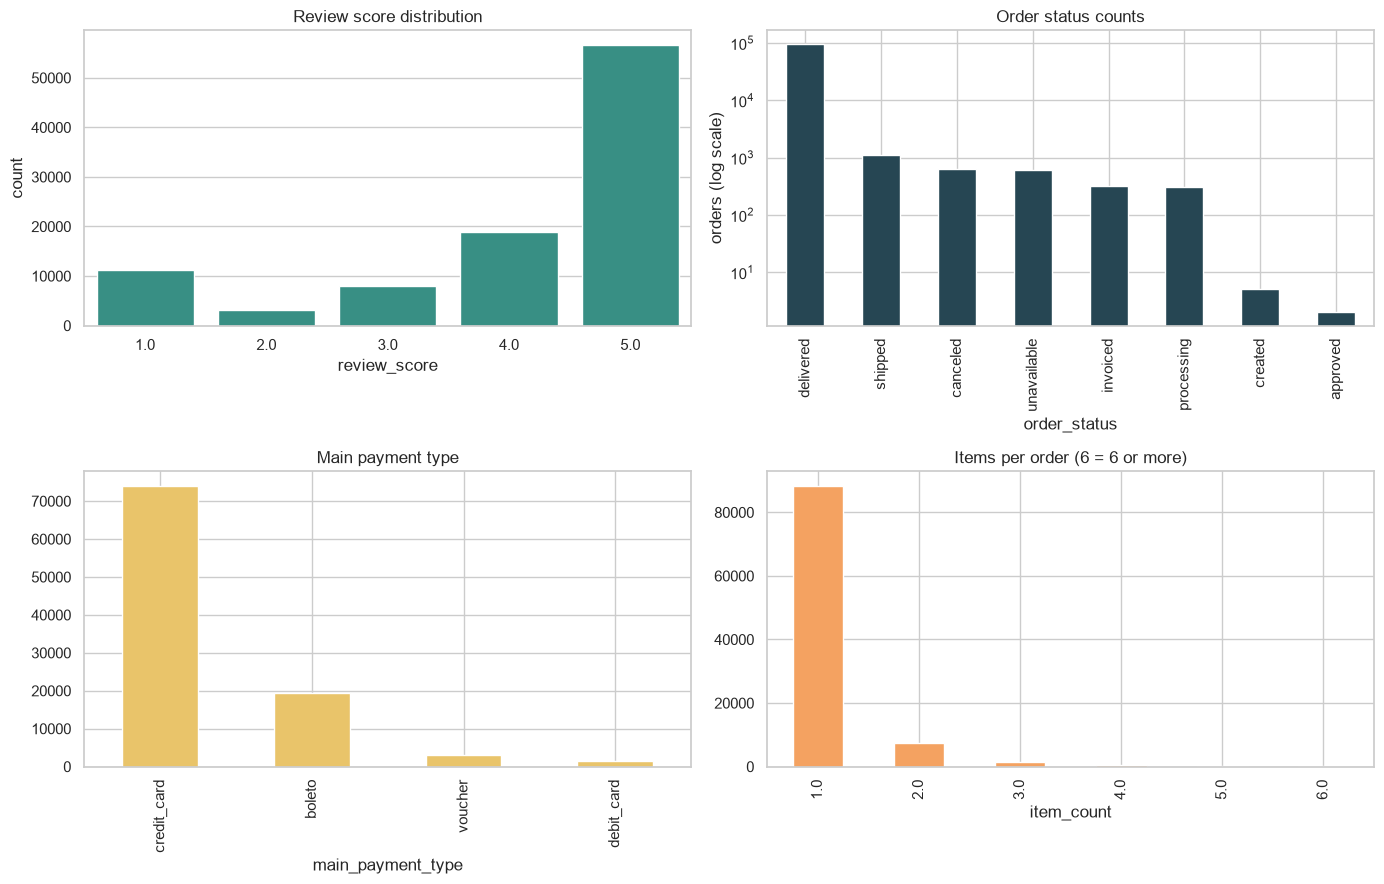

Share of 5-star reviews: 57.0 %
Share of credit card payments: 75.5 %
Share of single-item orders: 90.1 %


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Review score distribution
sns.countplot(data=order_features.dropna(subset=["review_score"]), x="review_score",
              color="#2a9d8f", ax=axes[0, 0])
axes[0, 0].set_title("Review score distribution")

# 2. Order status
order_features["order_status"].value_counts().plot(kind="bar", color="#264653", ax=axes[0, 1])
axes[0, 1].set_title("Order status counts")
axes[0, 1].set_yscale("log")
axes[0, 1].set_ylabel("orders (log scale)")

# 3. Payment type
valid["main_payment_type"].value_counts().plot(kind="bar", color="#e9c46a", ax=axes[1, 0])
axes[1, 0].set_title("Main payment type")

# 4. Number of items per order
valid["item_count"].clip(upper=6).value_counts().sort_index().plot(kind="bar", color="#f4a261", ax=axes[1, 1])
axes[1, 1].set_title("Items per order (6 = 6 or more)")

save("01_univariate")

print("Share of 5-star reviews:", round((order_features["review_score"] == 5).mean() * 100, 1), "%")
print("Share of credit card payments:", round((valid["main_payment_type"] == "credit_card").mean() * 100, 1), "%")
print("Share of single-item orders:", round((valid["item_count"] == 1).mean() * 100, 1), "%")

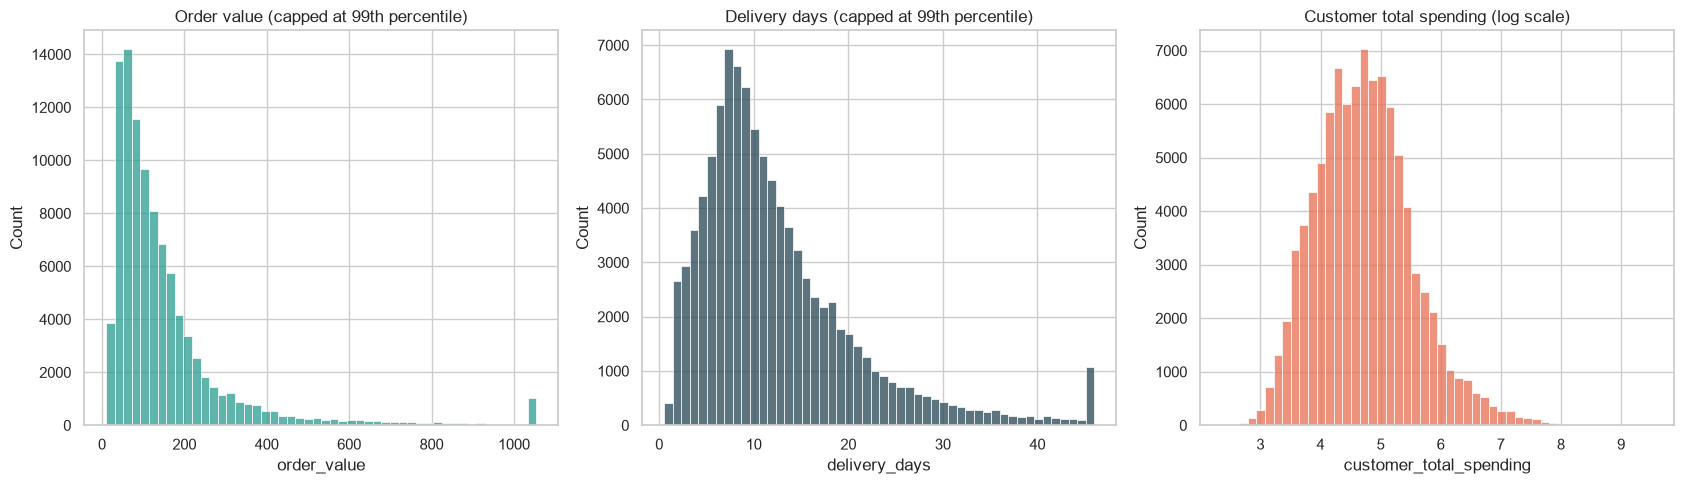

Skewness:
  order_value: 9.26
  delivery_days: 3.83
  customer_total_spending: 9.11

Median order value: 105.28 | Mean: 160.27
Median delivery days: 10.2 | Mean: 12.6


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Order value (cut at the 99th percentile so a few huge orders don't flatten the chart)
cap = valid["order_value"].quantile(0.99)
sns.histplot(valid["order_value"].clip(upper=cap), bins=50, color="#2a9d8f", ax=axes[0])
axes[0].set_title("Order value (capped at 99th percentile)")

# Delivery days
cap = delivered["delivery_days"].quantile(0.99)
sns.histplot(delivered["delivery_days"].clip(upper=cap), bins=50, color="#264653", ax=axes[1])
axes[1].set_title("Delivery days (capped at 99th percentile)")

# Customer total spending, on a log scale because it is highly skewed
sns.histplot(np.log1p(customer_features["customer_total_spending"]), bins=50, color="#e76f51", ax=axes[2])
axes[2].set_title("Customer total spending (log scale)")

save("02_distributions")

print("Skewness:")
print("  order_value:", round(valid["order_value"].skew(), 2))
print("  delivery_days:", round(delivered["delivery_days"].skew(), 2))
print("  customer_total_spending:", round(customer_features["customer_total_spending"].skew(), 2))
print("\nMedian order value:", round(valid["order_value"].median(), 2),
      "| Mean:", round(valid["order_value"].mean(), 2))
print("Median delivery days:", round(delivered["delivery_days"].median(), 1),
      "| Mean:", round(delivered["delivery_days"].mean(), 1))

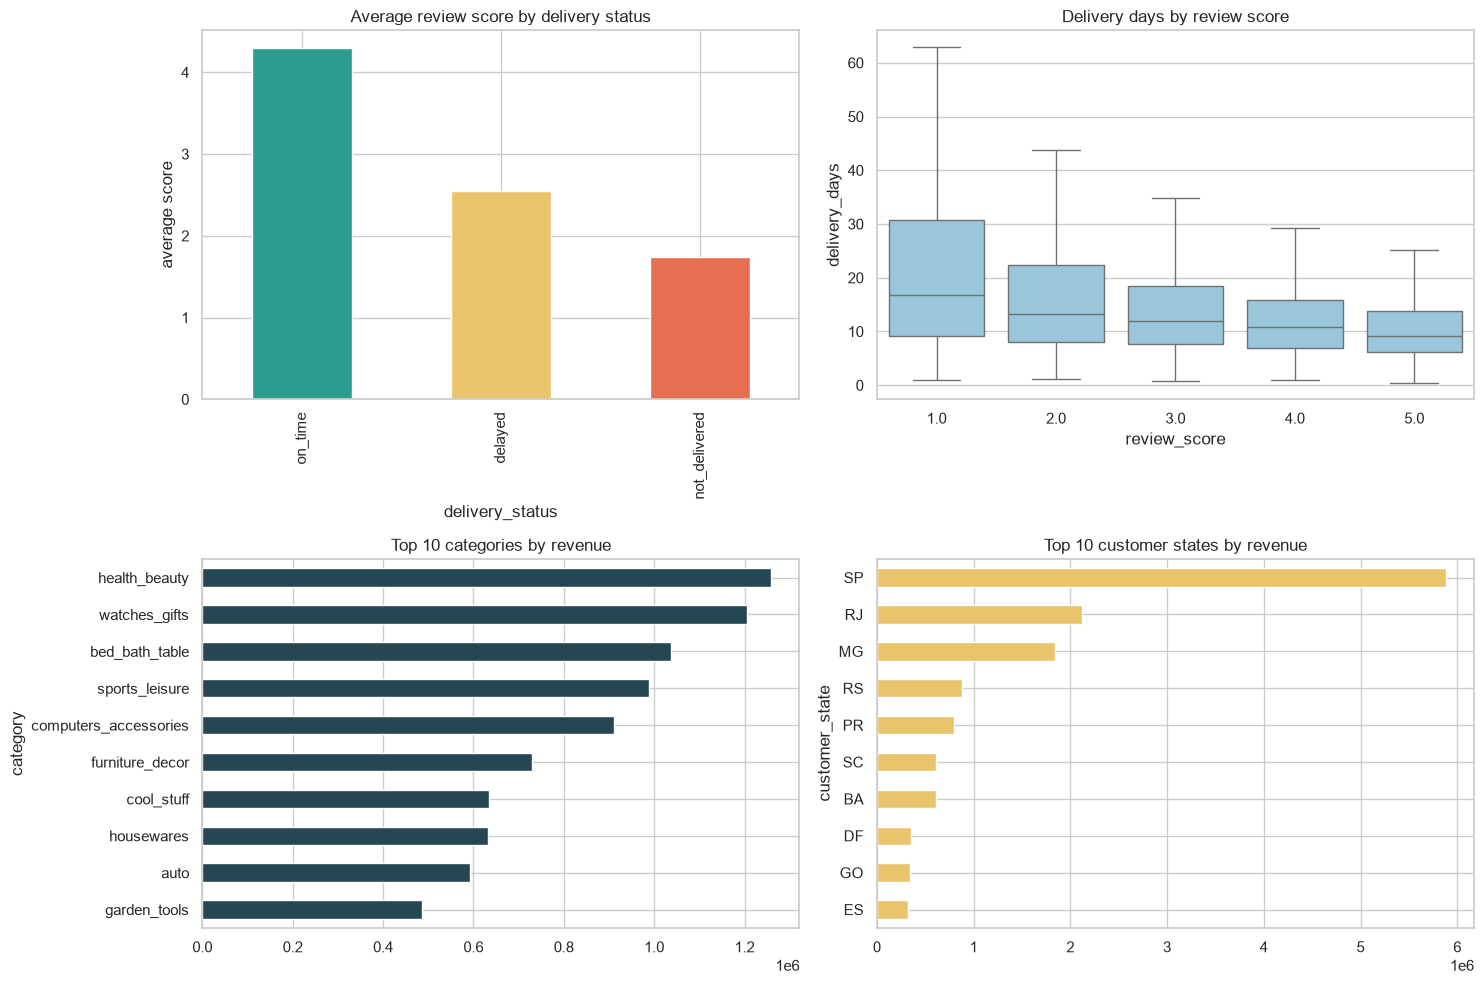

Average delivery days by review score:
review_score
1.0    21.4
2.0    16.7
3.0    14.3
4.0    12.3
5.0    10.7
Name: delivery_days, dtype: float64


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Average review score by delivery status
(order_features.groupby("delivery_status")["review_score"].mean()
 .reindex(["on_time", "delayed", "not_delivered"])
 .plot(kind="bar", color=["#2a9d8f", "#e9c46a", "#e76f51"], ax=axes[0, 0]))
axes[0, 0].set_title("Average review score by delivery status")
axes[0, 0].set_ylabel("average score")

# 2. Delivery days by review score
sns.boxplot(data=delivered.dropna(subset=["review_score"]), x="review_score", y="delivery_days",
            showfliers=False, color="#8ecae6", ax=axes[0, 1])
axes[0, 1].set_title("Delivery days by review score")

# 3. Top 10 categories by revenue
top_cat = (item_features.groupby("category")["price"].sum()
           .sort_values(ascending=False).head(10).sort_values())
top_cat.plot(kind="barh", color="#264653", ax=axes[1, 0])
axes[1, 0].set_title("Top 10 categories by revenue")

# 4. Top 10 states by revenue
top_state = (valid.groupby("customer_state")["order_value"].sum()
             .sort_values(ascending=False).head(10).sort_values())
top_state.plot(kind="barh", color="#e9c46a", ax=axes[1, 1])
axes[1, 1].set_title("Top 10 customer states by revenue")

save("03_bivariate")

print("Average delivery days by review score:")
print(delivered.groupby("review_score")["delivery_days"].mean().round(1))

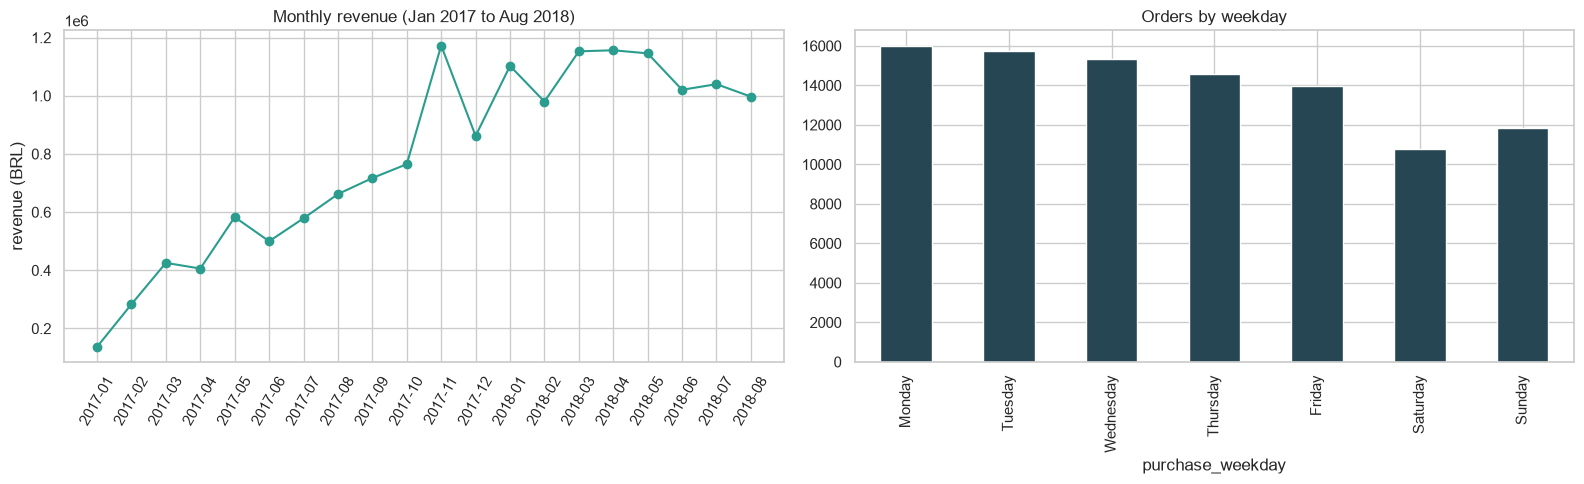

Best month: 2017-11 | revenue: 1172639.23
Revenue growth, first vs last full month: 628 %


In [5]:
monthly = (valid.groupby("purchase_month")
           .agg(revenue=("order_value", "sum"), orders=("order_id", "nunique"))
           .reset_index())

# The first and last months of the dataset are incomplete, so keep full months only
monthly = monthly[(monthly["purchase_month"] >= "2017-01") & (monthly["purchase_month"] <= "2018-08")]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(monthly["purchase_month"], monthly["revenue"], marker="o", color="#2a9d8f")
axes[0].set_title("Monthly revenue (Jan 2017 to Aug 2018)")
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_ylabel("revenue (BRL)")

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
valid["purchase_weekday"].value_counts().reindex(weekday_order).plot(kind="bar", color="#264653", ax=axes[1])
axes[1].set_title("Orders by weekday")

save("04_trend")

best = monthly.loc[monthly["revenue"].idxmax()]
print("Best month:", best["purchase_month"], "| revenue:", round(best["revenue"], 2))
print("Revenue growth, first vs last full month:",
      round((monthly["revenue"].iloc[-1] / monthly["revenue"].iloc[0] - 1) * 100), "%")

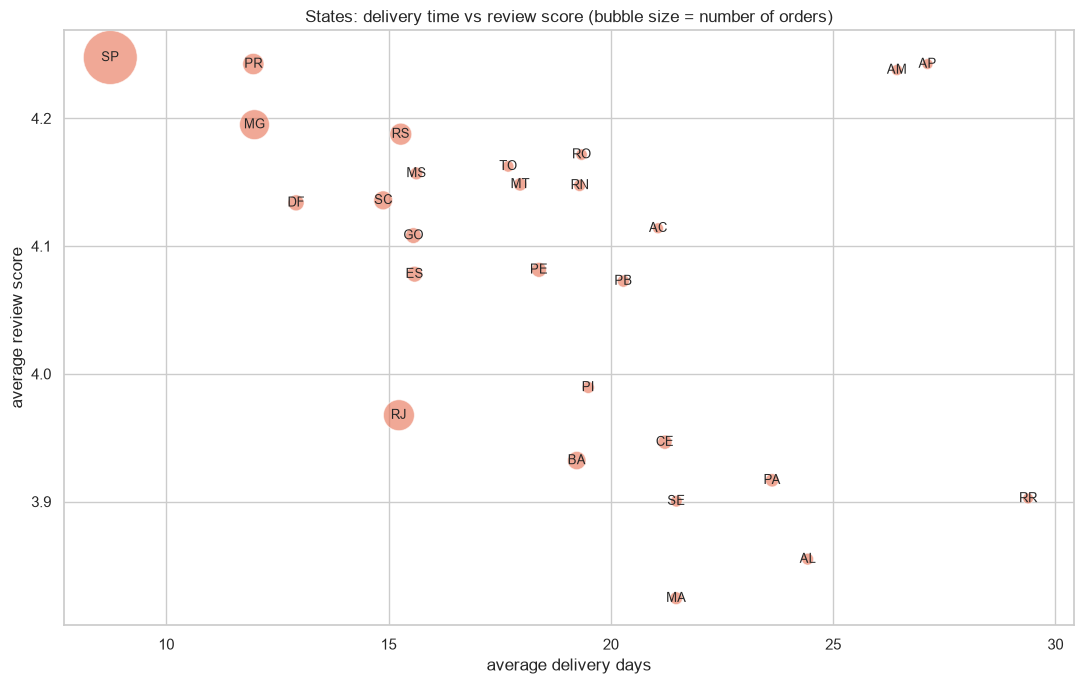

Correlation between a state's delivery time and its review score: -0.45


In [6]:
state_stats = (delivered.dropna(subset=["review_score"])
               .groupby("customer_state")
               .agg(orders=("order_id", "count"),
                    avg_delivery_days=("delivery_days", "mean"),
                    avg_review=("review_score", "mean"))
               .reset_index())

plt.figure(figsize=(11, 7))
sns.scatterplot(data=state_stats, x="avg_delivery_days", y="avg_review",
                size="orders", sizes=(60, 1500), alpha=0.6, color="#e76f51", legend=False)
for _, r in state_stats.iterrows():
    plt.text(r["avg_delivery_days"], r["avg_review"], r["customer_state"], ha="center", va="center", fontsize=9)
plt.title("States: delivery time vs review score (bubble size = number of orders)")
plt.xlabel("average delivery days")
plt.ylabel("average review score")
save("05_multivariate_states")

print("Correlation between a state's delivery time and its review score:",
      round(state_stats["avg_delivery_days"].corr(state_stats["avg_review"]), 2))

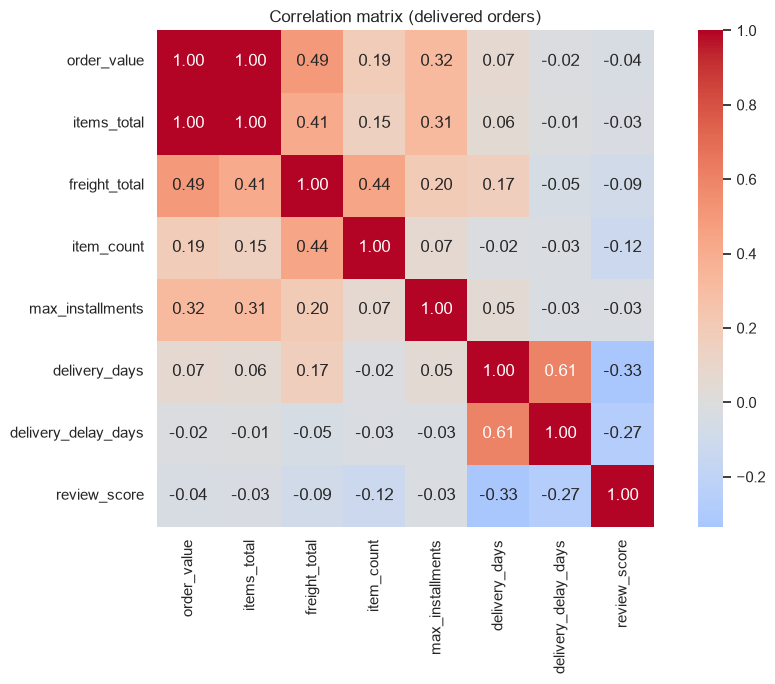

Strongest links with review_score:
delivery_days         -0.334634
delivery_delay_days   -0.267373
item_count            -0.123000
freight_total         -0.089536
order_value           -0.041413
items_total           -0.034063
max_installments      -0.030812
Name: review_score, dtype: float64


In [7]:
corr_cols = ["order_value", "items_total", "freight_total", "item_count", "max_installments",
             "delivery_days", "delivery_delay_days", "review_score"]
corr = delivered[corr_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (delivered orders)")
save("06_correlation")

print("Strongest links with review_score:")
print(corr["review_score"].drop("review_score").sort_values())

## EDA insights

- **Review scores:** X% of reviews are 5 stars, but there is a visible spike at 1 star, mostly from late or undelivered orders.
- **Order value:** the distribution is right-skewed. The median order is X BRL, the mean is X BRL, so a few large orders pull the average up.
- **Delivery:** the median delivery takes X days. Orders with low review scores took clearly longer to arrive.
- **Trend:** revenue grew strongly through 2017 and peaked in X (Black Friday season).
- **Geography:** SP, RJ and MG generate most of the revenue. Remote states have longer delivery times and lower review scores.
- **Correlation:** review_score correlates negatively with delivery_days and delivery_delay_days, and has almost no relationship with order_value.